# Sulav Dhungana
# Predicting radiation dose error from DVH features (OpenKBP-Opt)

Can the 23 DVH measurements of a treatment plan predict the plan's dose error relative to the reference plan?

**Part A** prepares the data. **Part B** trains and compares the models.

# Part A: Data preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

SEED = 20261118
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

## 1. Load the data
Two files from OpenKBP-Opt (`results-data` folder):
- `dose_error_df.csv`: mean absolute dose error of each plan vs. the reference plan (Gy). **This is our label.**
- `dvh_metric_df.csv`: DVH metrics of each plan (Gy). **These are our features.**

In [2]:
dose_error = pd.read_csv('data/dose_error_df.csv')
dvh = pd.read_csv('data/dvh_metric_df.csv')

print('dose_error:', dose_error.shape)
print('dvh:', dvh.shape)
display(dose_error.head(3))
display(dvh.head(3))

dose_error: (500, 21)
dvh: (11500, 23)


,Dose_type,Patients,set_1,set_10,set_11,set_12,set_13,set_14,set_15,set_16,...,set_18,set_19,set_2,set_3,set_4,set_5,set_6,set_7,set_8,set_9
0,Prediction,pt_241,2.388837,2.784895,2.936747,3.069860,2.782851,3.001371,2.542436,3.609892,...,4.051306,4.537533,2.392817,2.216111,2.812327,2.591578,2.355650,2.562408,2.364673,2.406698
1,Prediction,pt_325,3.429366,3.313683,2.978333,3.794322,3.549030,3.774881,3.396017,3.853913,...,4.988631,4.052206,3.178077,3.186578,3.450918,2.913521,2.972445,2.957143,3.397137,3.349499
2,Prediction,pt_259,1.908485,2.680077,2.616753,2.938098,3.285178,3.616683,2.734321,3.989797,...,3.853238,2.983228,2.242944,2.382182,2.349287,2.472027,2.384027,2.373174,2.339757,2.610082


,Dose_type,Patients,Metric,Structure,set_1,set_10,set_11,set_12,set_13,set_14,...,set_18,set_19,set_2,set_3,set_4,set_5,set_6,set_7,set_8,set_9
0,Prediction,pt_241,D_0.1_cc,Brainstem,27.586133,27.773866,27.658355,28.952257,27.547593,28.714386,...,28.508404,38.366998,25.608669,25.416086,27.177060,27.589417,26.740906,29.127920,26.885888,27.529621
1,Prediction,pt_241,D_0.1_cc,SpinalCord,33.077339,32.797612,32.945223,32.948815,32.790697,34.205895,...,32.993112,41.028966,31.767518,30.976161,33.419721,33.611332,31.511310,33.848626,34.345369,33.442051
2,Prediction,pt_241,D_0.1_cc,RightParotid,57.901592,57.745715,57.486486,55.724310,58.237855,57.996660,...,57.132655,56.524374,56.838500,57.022524,56.353105,57.777240,56.817668,56.106681,57.526215,57.570041


In [3]:
print(dose_error['Dose_type'].value_counts())
print('Patients:', dose_error['Patients'].nunique())

Dose_type
Prediction       100
absolute_mean    100
absolute_max     100
relative_max     100
relative_mean    100
Name: count, dtype: int64
Patients: 100


## 2. Keep only the treatment plans
`Dose_type = "Prediction"` rows are dose predictions, not plans, so we remove them.
The 4 remaining dose types are the optimizers that made the plans.

In [4]:
dose_error = dose_error[dose_error['Dose_type'] != 'Prediction']
dvh = dvh[dvh['Dose_type'] != 'Prediction']
print(dose_error['Dose_type'].unique())

['absolute_mean' 'absolute_max' 'relative_max' 'relative_mean']


## 3. Reshape to one row per plan
A plan = one patient + one prediction set + one optimizer.

In [5]:
# Label: one row per plan
target = dose_error.melt(id_vars=['Dose_type', 'Patients'], var_name='prediction_set', value_name='dose_error_gy')
target = target.rename(columns={'Dose_type': 'optimizer', 'Patients': 'patient_id'})
print(target.shape)
target.head()

(7600, 4)


,optimizer,patient_id,prediction_set,dose_error_gy
0,absolute_mean,pt_241,set_1,2.580584
1,absolute_mean,pt_325,set_1,2.176733
2,absolute_mean,pt_259,set_1,2.843918
3,absolute_mean,pt_323,set_1,5.291585
4,absolute_mean,pt_244,set_1,2.072885


In [6]:
# Features: one column per DVH metric, e.g. "D_99__PTV70"
dvh_long = dvh.melt(id_vars=['Dose_type', 'Patients', 'Metric', 'Structure'], var_name='prediction_set', value_name='value')
dvh_long['feature'] = dvh_long['Metric'] + '__' + dvh_long['Structure']

features = dvh_long.pivot(index=['Dose_type', 'Patients', 'prediction_set'], columns='feature', values='value')
features = features.reset_index().rename(columns={'Dose_type': 'optimizer', 'Patients': 'patient_id'})
features.columns.name = None
print(features.shape)

(7600, 26)


In [7]:
# The 23 DVH features in a fixed order
oars = ['Brainstem', 'SpinalCord', 'RightParotid', 'LeftParotid', 'Esophagus', 'Larynx', 'Mandible']
ptvs = ['PTV56', 'PTV63', 'PTV70']
FEATURES = [f'{m}__{s}' for s in oars for m in ['D_0.1_cc', 'mean']] + \
           [f'{m}__{s}' for s in ptvs for m in ['D_99', 'D_95', 'D_1']]
print(len(FEATURES), 'features')

23 features


In [8]:
# Join features and label
plans = features.merge(target, on=['optimizer', 'patient_id', 'prediction_set'], validate='one_to_one')
plans = plans[['patient_id', 'prediction_set', 'optimizer'] + FEATURES + ['dose_error_gy']]
print('Plans:', len(plans))
assert len(plans) == 100 * 19 * 4

Plans: 7600


## 4. Remove empty plans
Some plans have every DVH value equal to 0 Gy. These are not real plans (likely missing plan files).

In [9]:
empty = (plans[FEATURES].fillna(0) == 0).all(axis=1)
print('Empty plans:', empty.sum())

# Each patient's empty plans all have the same error -> error of a zero dose
plans[empty].groupby('patient_id')['dose_error_gy'].agg(['count', 'nunique', 'first'])

Empty plans: 61


,count,nunique,first
patient_id,,,
pt_250,11,1,16.631033
pt_311,1,1,16.572348
pt_327,39,1,13.883473
pt_339,10,1,19.539064


In [10]:
plans = plans[~empty]
plans = plans.sort_values(['patient_id', 'prediction_set', 'optimizer']).reset_index(drop=True)
print('Plans after removing empty plans:', len(plans))

Plans after removing empty plans: 7539


## 5. Missing values
A missing value means the patient does not have that structure (e.g. no PTV63). We keep these plans and fill the gaps later, using training data only.

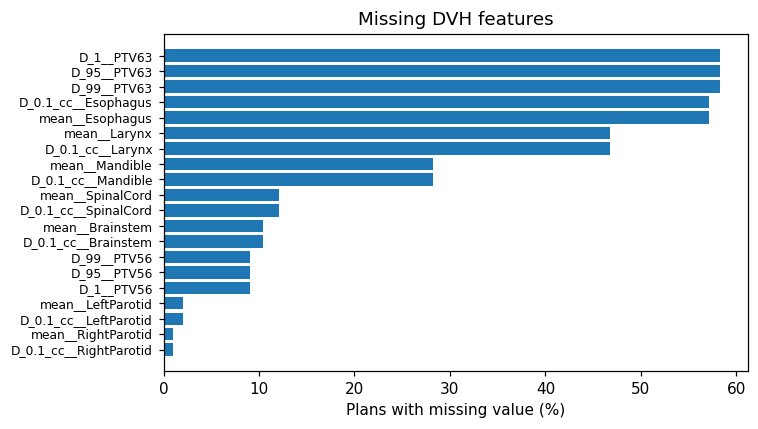

In [11]:
missing = plans[FEATURES].isna().mean() * 100
missing = missing[missing > 0].sort_values()

plt.figure(figsize=(7, 4))
plt.barh(missing.index, missing.values)
plt.xlabel('Plans with missing value (%)')
plt.title('Missing DVH features')
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Split by patient
All plans from one patient go into the same set, so the model is always tested on new patients.
60 train / 20 validation / 20 test patients.

In [12]:
patients = np.array(sorted(dose_error['Patients'].unique()))
shuffled = np.random.default_rng(SEED).permutation(patients)

splits = pd.DataFrame({'patient_id': shuffled,
                       'split': ['train'] * 60 + ['validation'] * 20 + ['test'] * 20})
splits = splits.sort_values('patient_id').reset_index(drop=True)

# Check: no patient is in two sets
train_p = set(splits[splits.split == 'train'].patient_id)
val_p = set(splits[splits.split == 'validation'].patient_id)
test_p = set(splits[splits.split == 'test'].patient_id)
assert not (train_p & val_p) and not (train_p & test_p) and not (val_p & test_p)

plans_split = plans.merge(splits, on='patient_id', how='left')
plans_split.groupby('split').agg(patients=('patient_id', 'nunique'), plans=('patient_id', 'size'))

,patients,plans
split,,
test,20,1510
train,60,4510
validation,20,1519


## 7. Look at the label (training patients only)

count    4510.00
mean        3.05
std         1.26
min         0.81
25%         2.16
50%         2.82
75%         3.75
max        13.91
Name: dose_error_gy, dtype: float64


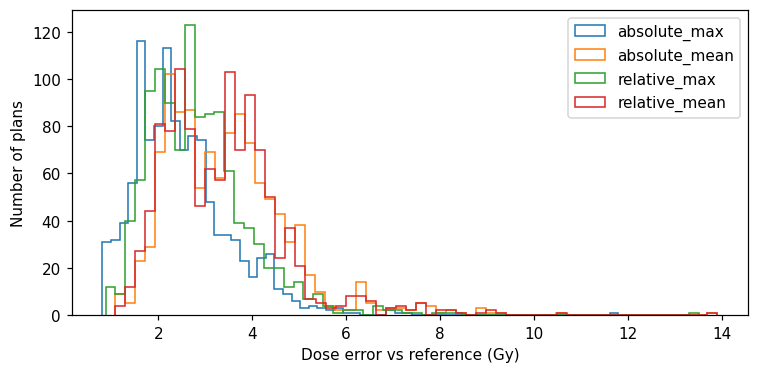

In [13]:
train = plans_split[plans_split.split == 'train']
print(train['dose_error_gy'].describe().round(2))

plt.figure(figsize=(7, 3.5))
for opt in ['absolute_max', 'absolute_mean', 'relative_max', 'relative_mean']:
    plt.hist(train.loc[train.optimizer == opt, 'dose_error_gy'], bins=60, histtype='step', label=opt)
plt.xlabel('Dose error vs reference (Gy)')
plt.ylabel('Number of plans')
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# How much of the variation is between patients vs between pipelines?
def variance_explained(df, group):
    y = df['dose_error_gy']
    group_mean = df.groupby(group)['dose_error_gy'].transform('mean')
    return 1 - ((y - group_mean) ** 2).sum() / ((y - y.mean()) ** 2).sum()

print('Patient:  ', round(variance_explained(train, 'patient_id'), 3))
print('Pipeline: ', round(variance_explained(train, ['prediction_set', 'optimizer']), 3))
print('Optimizer:', round(variance_explained(train, 'optimizer'), 3))
print('Pred. set:', round(variance_explained(train, 'prediction_set'), 3))

Patient:   0.705
Pipeline:  0.146
Optimizer: 0.095
Pred. set: 0.047


# Part B: Modeling
Compare models on **validation patients**. The test patients are used once at the end.

In [15]:
TARGET = 'dose_error_gy'
data = plans_split
train = data[data.split == 'train'].reset_index(drop=True)
val = data[data.split == 'validation'].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
print('Train plans:', len(train), '| Validation plans:', len(val))

Train plans: 4510 | Validation plans: 1519


In [16]:
def scores(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

## 1. Baselines
- **Mean baseline:** always predict the training mean.
- **Pipeline baseline:** predict the training mean of the plan's pipeline (prediction set + optimizer). No DVH used.

In [17]:
predictions = {}
predictions['Mean baseline'] = np.full(len(val), y_train.mean())

pipeline_means = train.groupby(['prediction_set', 'optimizer'])[TARGET].mean().rename('pred').reset_index()
pipeline_pred = val.merge(pipeline_means, on=['prediction_set', 'optimizer'], how='left')['pred']
predictions['Pipeline baseline'] = pipeline_pred.fillna(y_train.mean()).to_numpy()

pd.DataFrame({name: scores(y_val, p) for name, p in predictions.items()}).T

,MAE,RMSE,R2
Mean baseline,1.072145,1.504007,-0.029057
Pipeline baseline,1.069462,1.458841,0.031821


## 2. Ridge Regression
Missing values are filled with the training median (plus a "was missing" column), then scaled. Everything is inside the pipeline, so it is fit on training data only. Choose alpha by validation MAE.

In [18]:
ridge_results = []
for alpha in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    model = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), Ridge(alpha=alpha))
    model.fit(X_train, y_train)
    ridge_results.append({'alpha': alpha, **scores(y_val, model.predict(X_val))})

ridge_results = pd.DataFrame(ridge_results)
ridge_results

,alpha,MAE,RMSE,R2
0,0.001,0.914974,1.327065,0.198832
1,0.010,0.914974,1.327065,0.198831
2,0.100,0.914969,1.327068,0.198828
3,1.000,0.914917,1.327100,0.198789
4,10.000,0.914397,1.327358,0.198477
5,100.000,0.909150,1.326449,0.199575
6,1000.000,0.875238,1.297778,0.233803


In [19]:
best_alpha = ridge_results.loc[ridge_results.MAE.idxmin(), 'alpha']
ridge = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), Ridge(alpha=best_alpha))
ridge.fit(X_train, y_train)
predictions['Ridge'] = ridge.predict(X_val)
print('Best alpha:', best_alpha)

Best alpha: 1000.0


## 3. Random Forest
Small grid of settings. Choose by validation MAE. (Takes about 30 seconds.)

In [20]:
rf_results = []
for max_depth in [None, 10, 20]:
    for min_samples_leaf in [1, 5, 20]:
        for max_features in [1.0, 0.33]:
            model = make_pipeline(
                SimpleImputer(strategy='median', add_indicator=True),
                RandomForestRegressor(n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                      max_features=max_features, random_state=SEED, n_jobs=-1))
            model.fit(X_train, y_train)
            rf_results.append({'max_depth': max_depth, 'min_samples_leaf': min_samples_leaf,
                               'max_features': max_features, **scores(y_val, model.predict(X_val))})

rf_results = pd.DataFrame(rf_results)
rf_results.sort_values('MAE').head()

,max_depth,min_samples_leaf,max_features,MAE,RMSE,R2
1,NaN,1,0.33,0.828047,1.235703,0.305347
12,20.0,1,1.00,0.839340,1.197941,0.347154
0,NaN,1,1.00,0.840087,1.200341,0.344537
7,10.0,1,0.33,0.840133,1.259727,0.278075
13,20.0,1,0.33,0.840600,1.250138,0.289023


In [21]:
best_rf = rf_results.loc[rf_results.MAE.idxmin()]
best_depth = None if pd.isna(best_rf.max_depth) else int(best_rf.max_depth)
rf_settings = dict(n_estimators=300, max_depth=best_depth, min_samples_leaf=int(best_rf.min_samples_leaf),
                   max_features=float(best_rf.max_features), random_state=SEED, n_jobs=-1)

rf = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), RandomForestRegressor(**rf_settings))
rf.fit(X_train, y_train)
predictions['Random Forest'] = rf.predict(X_val)
print('Best settings:', rf_settings)

Best settings: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 0.33, 'random_state': 20261118, 'n_jobs': -1}


## 4. Validation results

In [22]:
results = pd.DataFrame({name: scores(y_val, p) for name, p in predictions.items()}).T
results.round(3)

,MAE,RMSE,R2
Mean baseline,1.072,1.504,-0.029
Pipeline baseline,1.069,1.459,0.032
Ridge,0.875,1.298,0.234
Random Forest,0.828,1.236,0.305


### 95% confidence intervals
Resample the 20 validation **patients** (not plans) 2,000 times.

In [23]:
rng = np.random.default_rng(SEED)
val_patients = val.patient_id.unique()
boot = {name: [] for name in predictions}
boot_diff = {name: [] for name in predictions}

for i in range(2000):
    sample = rng.choice(val_patients, size=len(val_patients), replace=True)
    rows = np.concatenate([np.flatnonzero(val.patient_id == p) for p in sample])
    y = y_val.to_numpy()[rows]
    base_mae = mean_absolute_error(y, predictions['Mean baseline'][rows])
    for name, p in predictions.items():
        mae = mean_absolute_error(y, p[rows])
        boot[name].append([mae, r2_score(y, p[rows])])
        boot_diff[name].append(mae - base_mae)

ci = pd.DataFrame({name: {'MAE low': np.percentile(np.array(b)[:, 0], 2.5),
                          'MAE high': np.percentile(np.array(b)[:, 0], 97.5),
                          'R2 low': np.percentile(np.array(b)[:, 1], 2.5),
                          'R2 high': np.percentile(np.array(b)[:, 1], 97.5),
                          'MAE diff vs mean, low': np.percentile(boot_diff[name], 2.5),
                          'MAE diff vs mean, high': np.percentile(boot_diff[name], 97.5)}
                   for name, b in boot.items()}).T
ci.round(2)

,MAE low,MAE high,R2 low,R2 high,"MAE diff vs mean, low","MAE diff vs mean, high"
Mean baseline,0.75,1.53,-0.27,-0.00,0.00,0.00
Pipeline baseline,0.76,1.52,-0.22,0.15,-0.03,0.03
Ridge,0.58,1.33,-0.07,0.58,-0.40,-0.03
Random Forest,0.54,1.27,0.03,0.61,-0.44,-0.06


### Predicted vs actual

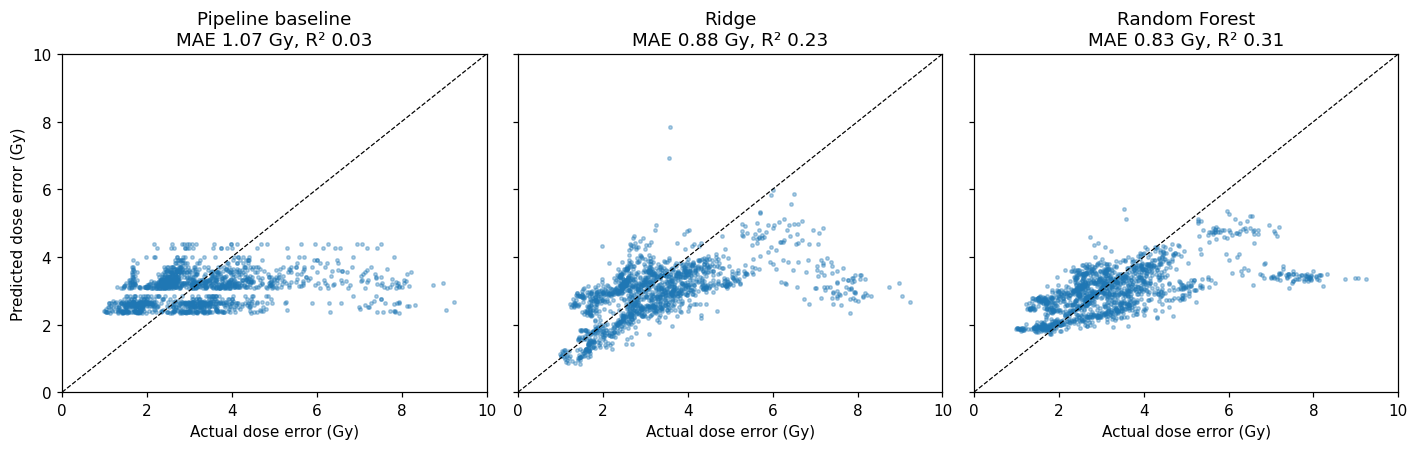

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, name in zip(axes, ['Pipeline baseline', 'Ridge', 'Random Forest']):
    ax.scatter(y_val, predictions[name], s=5, alpha=0.35)
    ax.plot([0, 10], [0, 10], 'k--', lw=0.8)
    ax.set_title(f"{name}\nMAE {results.loc[name, 'MAE']:.2f} Gy, R² {results.loc[name, 'R2']:.2f}")
    ax.set_xlabel('Actual dose error (Gy)')
    ax.set_xlim(0, 10); ax.set_ylim(0, 10)
axes[0].set_ylabel('Predicted dose error (Gy)')
plt.tight_layout()
plt.show()

### Ranking plans within one patient
Spearman correlation between predicted and actual error inside each validation patient.

In [25]:
val_pred = val[['patient_id', TARGET]].copy()
for name in ['Pipeline baseline', 'Ridge', 'Random Forest']:
    val_pred[name] = predictions[name]

within = {}
for name in ['Pipeline baseline', 'Ridge', 'Random Forest']:
    within[name] = val_pred.groupby('patient_id').apply(
        lambda g: g[TARGET].corr(g[name], method='spearman'), include_groups=False)
pd.DataFrame(within).median().round(3).rename('median Spearman')

Pipeline baseline    0.812
Ridge                0.714
Random Forest        0.757
Name: median Spearman, dtype: float64

### Feature importance (Random Forest)
How much worse the validation MAE gets when one feature is shuffled.

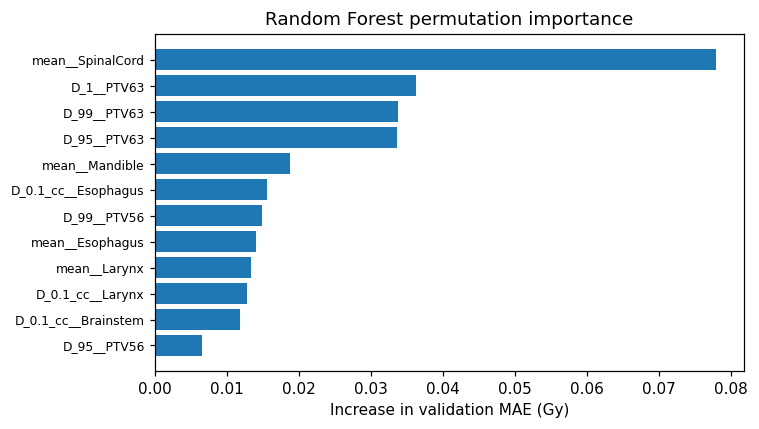

In [26]:
imp = permutation_importance(rf, X_val, y_val, scoring='neg_mean_absolute_error',
                             n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(12)

plt.figure(figsize=(7, 4))
plt.barh(importance.index, importance.values)
plt.xlabel('Increase in validation MAE (Gy)')
plt.title('Random Forest permutation importance')
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Why we split by patient
Same Random Forest, but split the train + validation plans at random (a patient's plans end up on both sides).

In [27]:
trainval = pd.concat([train, val], ignore_index=True)
idx_a, idx_b = train_test_split(np.arange(len(trainval)), test_size=len(val), random_state=SEED)

rf_random = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), RandomForestRegressor(**rf_settings))
rf_random.fit(trainval.loc[idx_a, FEATURES], trainval.loc[idx_a, TARGET])
random_scores = scores(trainval.loc[idx_b, TARGET], rf_random.predict(trainval.loc[idx_b, FEATURES]))

shared = set(trainval.loc[idx_a, 'patient_id']) & set(trainval.loc[idx_b, 'patient_id'])
print('Patients on both sides of the random split:', len(shared))
pd.DataFrame({'Random plan split (wrong)': random_scores,
              'Patient split (correct)': scores(y_val, predictions['Random Forest'])}).T.round(3)

Patients on both sides of the random split: 80


,MAE,RMSE,R2
Random plan split (wrong),0.192,0.319,0.938
Patient split (correct),0.828,1.236,0.305


## 6. Final test (run once, at the very end)
Refit the chosen models on train + validation patients, then score the 20 test patients. Set `RUN_TEST = True` only for the final report.

In [28]:
RUN_TEST = False

if RUN_TEST:
    test = data[data.split == 'test'].reset_index(drop=True)
    X_tv, y_tv = trainval[FEATURES], trainval[TARGET]

    final_ridge = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                                Ridge(alpha=best_alpha)).fit(X_tv, y_tv)
    final_rf = make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                             RandomForestRegressor(**rf_settings)).fit(X_tv, y_tv)
    tv_pipeline_means = trainval.groupby(['prediction_set', 'optimizer'])[TARGET].mean().rename('pred').reset_index()

    test_pred = {
        'Mean baseline': np.full(len(test), y_tv.mean()),
        'Pipeline baseline': test.merge(tv_pipeline_means, on=['prediction_set', 'optimizer'],
                                        how='left')['pred'].fillna(y_tv.mean()).to_numpy(),
        'Ridge': final_ridge.predict(test[FEATURES]),
        'Random Forest': final_rf.predict(test[FEATURES]),
    }
    display(pd.DataFrame({name: scores(test[TARGET], p) for name, p in test_pred.items()}).T.round(3))
else:
    print('Test set not used yet.')

Test set not used yet.
